# 2. Ventanas, objetivos multipaso y validación cruzada temporal (timeseries-cv)

**Objetivo del capítulo.** Construir las ventanas de entrada (lags de 7, 14, 21 y 28 días) y los objetivos
multisalida (horizontes de 7, 14, 21 y 28 días), y entender con exactitud qué hace cada una de las tres
estrategias de `tsxv.splitTrainVal` antes de entrenar nada: cuántos folds genera, qué tramos usa para entrenar
y para validar, y si respeta o no el orden del tiempo.

**Resultado:** el diseño de folds que se usa en los capítulos 3 a 7, con sus comprobaciones de integridad.

In [1]:
import inspect
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np
import pandas as pd
import tsxv
from IPython.display import Markdown, display
from matplotlib.patches import Patch
from tsxv.splitTrainVal import split_train_val_forwardChaining

from fcst.cv import STRATEGY_LABEL, check_no_leak, make_folds, search_split, tsxv_window_starts, windows
from fcst.features import holdout_split
from fcst.nbutils import MUTED, PART_COLOR, plt, savefig, setup

cfg, RES, FIG = setup()
series = pd.read_csv(RES / "serie_modelado.csv", parse_dates=["Date"])
y = series.Close.values
sp = holdout_split(len(y), cfg["holdout_frac"], cfg["horizons"])
y_cv = y[:sp.n_cv]
C = cfg["cv"]
print(f"Serie de CV: {sp.n_cv} días · hold-out: {sp.n_hold} días · timeseries-cv {getattr(tsxv, '__version__', '0.1.5')}")

Perfil: full  |  resultados en: /content/deep-learning-02-forecasting-mlp/results
Serie de CV: 2903 días · hold-out: 322 días · timeseries-cv 0.1.5


## 2.1 Ventanas y objetivos multipaso

Con un tamaño de entrada `lag` y un horizonte `H`, cada muestra es una ventana: la entrada son los `lag` cierres
consecutivos y el objetivo son los `H` cierres siguientes (salida multisalida de longitud H). Ejemplo con los
primeros días, lag = 7 y H = 7:

In [2]:
X_demo, y_demo = windows(y_cv, np.arange(3), 7, 7)
pd.DataFrame(np.c_[X_demo, y_demo], columns=[f"x(t-{7 - i})" for i in range(7)] + [f"y(t+{h})" for h in range(1, 8)],
             index=[f"ventana {i}" for i in range(3)]).round(0)

,x(t-7),x(t-6),x(t-5),x(t-4),x(t-3),x(t-2),x(t-1),y(t+1),y(t+2),y(t+3),y(t+4),y(t+5),y(t+6),y(t+7)
ventana 0,14675.0,14920.0,15060.0,16960.0,17070.0,16150.0,14903.0,14400.0,14907.0,13239.0,13740.0,14210.0,13475.0,13540.0
ventana 1,14920.0,15060.0,16960.0,17070.0,16150.0,14903.0,14400.0,14907.0,13239.0,13740.0,14210.0,13475.0,13540.0,10900.0
ventana 2,15060.0,16960.0,17070.0,16150.0,14903.0,14400.0,14907.0,13239.0,13740.0,14210.0,13475.0,13540.0,10900.0,10989.0


## 2.2 Qué devuelve realmente tsxv

Las tres funciones comparten la firma `f(sequence, numInputs, numOutputs, numJumps)` y devuelven diccionarios
`X, y, Xcv, ycv` indexados por fold. **Ojo:** el borrador de la guía las llama con argumentos con nombre
(`n_steps_input=...`), que no existen en la librería publicada en PyPI; aquí se llaman por posición.

Para saber qué ventanas usa cada fold se llama a tsxv con la secuencia de índices 0..n−1: cada ventana devuelta
empieza en su propio índice. La tabla resume, para el caso más exigente (lag = 28, H = 28), cuántos folds genera
cada estrategia y cuántas ventanas tiene cada uno.

In [3]:
print(inspect.signature(split_train_val_forwardChaining))
rows = []
for st in C["strategies"]:
    for lag, H in [(7, 7), (28, 28)]:
        lib = tsxv_window_starts(st, sp.n_cv, lag, H, C["n_steps_jump"])
        ntr = np.array([len(t) for t, _ in lib]); nva = np.array([len(v) for _, v in lib])
        rows.append({"estrategia": STRATEGY_LABEL[st], "lag": lag, "H": H, "folds de tsxv": len(lib),
                     "ventanas de validación por fold": f"{nva.min()}–{nva.max()}",
                     "ventanas de entrenamiento por fold": f"{ntr.min()}–{ntr.max()}"})
raw_tsxv = pd.DataFrame(rows)
raw_tsxv.to_csv(RES / "tsxv_folds_crudos.csv", index=False)
raw_tsxv

(sequence, numInputs, numOutputs, numJumps)


,estrategia,lag,H,folds de tsxv,ventanas de validación por fold,ventanas de entrenamiento por fold
0,Group K-Fold,7,7,5,170–170,679–680
1,Group K-Fold,28,28,5,48–49,192–196
2,Forward Chaining,7,7,2882,1–1,2–2883
3,Forward Chaining,28,28,2819,1–1,2–2820
4,K-Fold,7,7,2882,1–1,2877–2883
5,K-Fold,28,28,2819,1–1,2793–2820


**Hallazgos sobre la librería** (condicionan todo el diseño):

1. **Forward Chaining y K-Fold** generan un fold por cada salto (`numJumps`) y cada fold valida **una sola
   ventana**. Con `numJumps = 1` resultan miles de folds: entrenar una red por fold es inviable y el test BDS no
   se puede calcular con un solo residuo. Subir `numJumps` reduce los folds, pero también descarta ventanas de
   entrenamiento (solo usa una de cada `numJumps`).
2. **Group K-Fold** devuelve siempre 5 folds, pero intercala: cuatro ventanas de entrenamiento consecutivas,
   una de validación, y vuelve a empezar después de esta. Los "grupos" de validación no son tramos contiguos: están
   repartidos por toda la serie, y cada fold usa pocas ventanas de entrenamiento.
3. En K-Fold y Group K-Fold hay ventanas de entrenamiento **posteriores** a las de validación: el modelo aprende
   del futuro para predecir el pasado.

**Diseño adoptado.** Se respeta lo que tsxv define como entrenamiento y validación en cada fold, con dos ajustes
documentados:

* En Forward Chaining y K-Fold se agrupan los folds consecutivos de tsxv en **5 bloques** sobre la segunda mitad
  de la serie de CV. En cada bloque se entrena una sola red con las ventanas que tsxv marca como de
  entrenamiento en **todos** los folds del bloque, y se validan todas las ventanas del bloque. En Forward
  Chaining eso equivale a un *walk-forward* que se reentrena cada ~20 % del tramo de validación.
* En todas las estrategias se **purgan** las ventanas de entrenamiento cuyo objetivo se solapa con el objetivo
  de alguna ventana de validación. Si la purga deja menos de 50 ventanas (ocurre en Group K-Fold cuando H es
  grande frente al espaciado de sus ventanas de validación), se usa el fold tal cual y se registra la fuga.

## 2.3 Esquema de cada estrategia

Para lag = 14 y H = 14: cada fila es un fold; azul = inicio de una ventana de entrenamiento, naranja = inicio
de una ventana de validación, verde = hold-out final reservado.

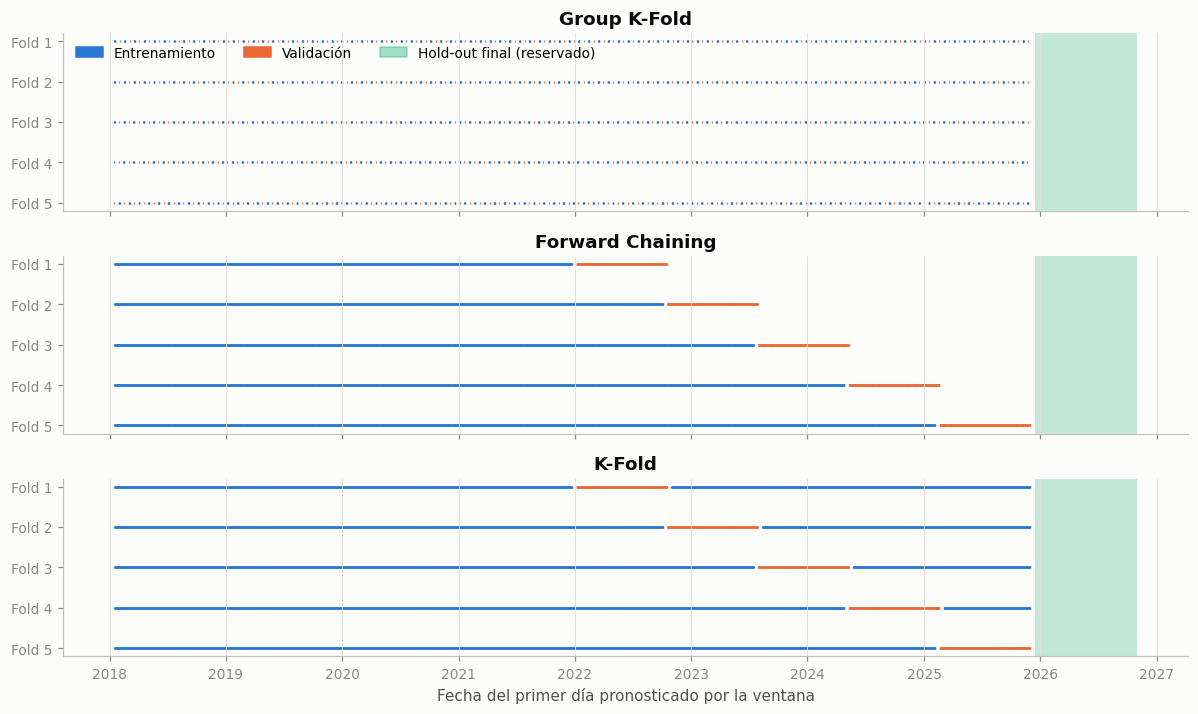

In [4]:
lag_s, H_s = 14, 14
fig, axes = plt.subplots(3, 1, figsize=(11, 6.6), sharex=True)
for ax, st in zip(axes, C["strategies"]):
    folds = make_folds(st, sp.n_cv, lag_s, H_s, C["n_steps_jump"], C["n_blocks"], C["min_train_frac"])
    for f in folds:
        yy = len(folds) - f.k
        ax.scatter(series.Date.iloc[f.train + lag_s], np.full(len(f.train), yy), s=3, marker="|",
                   color=PART_COLOR["train"], linewidths=0.8)
        ax.scatter(series.Date.iloc[f.val + lag_s], np.full(len(f.val), yy), s=3, marker="|",
                   color=PART_COLOR["val"], linewidths=0.8)
    ax.axvspan(series.Date.iloc[sp.n_cv], series.Date.iloc[-1], color=PART_COLOR["hold"], alpha=0.25, lw=0)
    ax.set_yticks(range(1, len(folds) + 1), [f"Fold {len(folds) - i}" for i in range(len(folds))])
    ax.set_title(STRATEGY_LABEL[st]); ax.grid(axis="y", visible=False)
axes[0].legend(handles=[Patch(color=PART_COLOR["train"], label="Entrenamiento"),
                        Patch(color=PART_COLOR["val"], label="Validación"),
                        Patch(color=PART_COLOR["hold"], alpha=0.4, label="Hold-out final (reservado)")],
               loc="upper left", ncol=3)
axes[-1].set_xlabel("Fecha del primer día pronosticado por la ventana")
savefig(fig, FIG, "02_esquema_estrategias")
plt.show()

## 2.4 Comprobaciones de integridad de todos los folds

Para cada estrategia × lag × horizonte se verifica: (a) cuántas ventanas de entrenamiento y validación quedan,
(b) si la purga se pudo aplicar, y (c) si todo el entrenamiento queda en el pasado respecto a la validación
(solo debe cumplirse en Forward Chaining).

In [5]:
rows = []
for st in C["strategies"]:
    for lag in cfg["lags"]:
        for H in cfg["horizons"]:
            for f in make_folds(st, sp.n_cv, lag, H, C["n_steps_jump"], C["n_blocks"], C["min_train_frac"]):
                rows.append({"lag": lag, "H": H, "fold": f.k + 1, "folds_tsxv_agrupados": f.n_lib_folds,
                             **check_no_leak(f, lag, H, st)})
integ = pd.DataFrame(rows)
integ.to_csv(RES / "cv_integridad.csv", index=False)
resumen = integ.groupby("estrategia").agg(
    folds=("fold", "count"), ventanas_train_media=("ventanas_train", "mean"),
    ventanas_val_media=("ventanas_val", "mean"), folds_sin_purga=("purgado", lambda s: int((~s).sum())),
    train_siempre_en_el_pasado=("train_todo_en_el_pasado", "all")).round(1)
resumen.index = resumen.index.map(STRATEGY_LABEL)
resumen

,folds,ventanas_train_media,ventanas_val_media,folds_sin_purga,train_siempre_en_el_pasado
estrategia,,,,,
Forward Chaining,80,1997.7,283.6,0,True
Group K-Fold,80,374.2,93.6,30,False
K-Fold,80,2547.8,283.6,0,False


In [6]:
fc_ok = integ.query("estrategia == 'forwardChaining'").train_todo_en_el_pasado.all()
assert fc_ok, "Forward Chaining debe entrenar siempre con el pasado"
display(Markdown(
    f"Forward Chaining entrena **siempre** con el pasado ({'verificado' if fc_ok else 'FALLA'}). "
    "K-Fold y Group K-Fold no: parte de su entrenamiento es posterior a la validación, de modo que su error de "
    "validación puede ser optimista. Esa diferencia es justo lo que se mide en el capítulo 4."))

Forward Chaining entrena **siempre** con el pasado (verificado). K-Fold y Group K-Fold no: parte de su entrenamiento es posterior a la validación, de modo que su error de validación puede ser optimista. Esa diferencia es justo lo que se mide en el capítulo 4.

## 2.5 Split de la búsqueda de arquitectura

La búsqueda (capítulo 3) necesita un solo entrenamiento por candidato. Se usa la estrategia principal,
**Forward Chaining**, con origen en el 80 % de la serie de CV: se entrena con las ventanas del fold de tsxv cuya
validación empieza en ese origen y se valida con **todas** las ventanas de validación posteriores. El hold-out
final sigue intacto.

In [7]:
rows = []
for lag in cfg["lags"]:
    for H in cfg["horizons"]:
        f = search_split(sp.n_cv, lag, H, cfg["search"]["origin_frac"], C["n_steps_jump"])
        rows.append({"lag": lag, "H": H, "ventanas_train": len(f.train), "ventanas_val": len(f.val),
                     "train_hasta": series.Date.iloc[f.train.max() + lag + H - 1].date(),
                     "val_desde": series.Date.iloc[f.val.min() + lag].date(),
                     "val_hasta": series.Date.iloc[f.val.max() + lag + H - 1].date()})
split_busqueda = pd.DataFrame(rows)
split_busqueda.to_csv(RES / "split_busqueda.csv", index=False)
split_busqueda

,lag,H,ventanas_train,ventanas_val,train_hasta,val_desde,val_hasta
0,7,7,2316,568,2024-05-18,2024-05-19,2025-12-13
1,7,14,2309,561,2024-05-18,2024-05-19,2025-12-13
2,7,21,2302,554,2024-05-18,2024-05-19,2025-12-13
3,7,28,2295,547,2024-05-18,2024-05-19,2025-12-13
4,14,7,2309,561,2024-05-18,2024-05-26,2025-12-13
5,14,14,2309,554,2024-05-25,2024-05-26,2025-12-13
6,14,21,2302,547,2024-05-25,2024-05-26,2025-12-13
7,14,28,2295,540,2024-05-25,2024-05-26,2025-12-13
8,21,7,2302,554,2024-05-18,2024-06-02,2025-12-13
9,21,14,2302,547,2024-05-25,2024-06-02,2025-12-13
